---
title: "L3-01 · Complex numbers and phase"
short_title: "Complex numbers and phase"
subtitle: "A complex number is an arrow with a length and an angle; multiplying arrows multiplies lengths and adds angles, and that is why phase can make quantities cancel."
description: "Compute the modulus, argument, conjugate and polar form of a complex number, and explain why multiplication by a unit complex number is a rotation."
tags: [level-3, coursebook]
---

(lesson-l3-01)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 75 minutes  
**Big idea.** A complex number is an arrow with a length and an angle; multiplying arrows multiplies lengths and adds angles, and that is why phase can make quantities cancel.  
**Before this lesson.** [L2-09](#lesson-l2-09)  
**Lab.** [Interference](../../labs/04-interference.ipynb)
:::

## What you will be able to do

- Compute $|z|$, $\arg z$ and $\bar z$ for a complex number, and convert between $a + bi$ and $r e^{i\theta}$.
- Explain multiplication by $e^{i\theta}$ as a rotation that keeps length, using Euler's formula.
- Show that $|1 + e^{i\varphi}|^2 = 2 + 2\cos\varphi$ and say what it means for two equal-size contributions in and out of step.

## Why this matters

Two waves of the same size can add to something twice as large or cancel to nothing. Ordinary positive numbers cannot do that, because adding positive amounts never gives zero. Complex numbers can, because each one carries an angle as well as a size.

Quantum theory writes every amplitude as a complex number. The probability of an outcome uses only the squared length, but the angles decide how amplitudes combine before that square is taken. This lesson builds the arithmetic you need for every later level: lengths, angles, conjugates and rotations.

:::{dropdown} Key terms

**Complex plane**
: The plane whose horizontal axis is the real part and whose vertical axis is the imaginary part of a number $a + bi$.

**Modulus**
: The length $|z| = \sqrt{a^2 + b^2}$ of the arrow from 0 to $z$.

**Argument (phase)**
: The angle $\theta$ from the positive real axis to the arrow, defined up to whole turns of $2\pi$.

**Complex conjugate**
: $\bar z = a - bi$, the reflection of $z = a + bi$ in the real axis.

**Polar form**
: $z = r e^{i\theta}$ with $r = |z|$ and $\theta = \arg z$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_01 as _lessonfigs

## Numbers as points and arrows

Write a complex number as $z = a + bi$, where $a$ and $b$ are real and $i^2 = -1$. Plot it at the point $(a, b)$, or think of it as the arrow from $0$ to that point. Adding complex numbers adds arrows head to tail, exactly like adding vectors in [L2-09](#lesson-l2-09).

:::{prf:definition} Modulus, argument and conjugate
:label: def-l3-01-modulus
For $z = a + bi$, the **modulus** is $|z| = \sqrt{a^2 + b^2}$, an **argument** is any angle $\theta$ with $\cos\theta = a/|z|$ and $\sin\theta = b/|z|$, and the **conjugate** is $\bar z = a - bi$.
:::

:::{figure} ../../_static/animations/l3_01_complex_plane.mp4
:alt: The point z = 3 + 4i on a complex plane, its arrow of length 5, the angle of about 53 degrees, and its mirror image 3 - 4i.
:width: 100%

One number, three views: coordinates $3 + 4i$, length and angle, and the polar form $5e^{i\,0.927}$.
:::

:::{dropdown} What the animation shows
The animation marks $z = 3 + 4i$, draws the legs 3 and 4 and the arrow, and computes $|z| = \sqrt{3^2 + 4^2} = \sqrt{25} = 5$. It shows the angle $\theta = \arctan(4/3) \approx 53.13^\circ$. It then reflects the arrow in the real axis to get $\bar z = 3 - 4i$ and multiplies: $z\bar z = 9 + 16 = 25 = |z|^2$. Finally it writes the same point as $z = 5e^{i\,0.927}$, length 5 and angle 0.927 radians.
:::

$$
z\,\bar z = (a + bi)(a - bi) = a^2 + b^2 = |z|^2
$$ (eq-l3-01-zzbar)

Equation [](#eq-l3-01-zzbar) is the most used identity in this course. For $z = 3 + 4i$ it gives $z\bar z = 9 + 16 = 25$, so $|z| = 5$. The angle is $\arctan(4/3) \approx 53.13^\circ$, or $0.927$ radians.

## Polar form and Euler's formula

:::{prf:theorem} Euler's formula
:label: thm-l3-01-euler
For every real $\theta$, $\; e^{i\theta} = \cos\theta + i\sin\theta$.
:::

:::{prf:proof}
Compare power series. $e^{x} = \sum_{k \ge 0} x^k / k!$ converges for every complex $x$. Put $x = i\theta$ and use $i^2 = -1$, $i^3 = -i$, $i^4 = 1$. The even terms give $1 - \theta^2/2! + \theta^4/4! - \dots = \cos\theta$, and the odd terms give $i(\theta - \theta^3/3! + \dots) = i\sin\theta$.
:::

So every complex number can be written $z = r e^{i\theta}$ with $r = |z|$. In polar form multiplication is easy: $r_1 e^{i\theta_1} \cdot r_2 e^{i\theta_2} = r_1 r_2\, e^{i(\theta_1 + \theta_2)}$. Lengths multiply and angles add [@openstax_polar].

:::{important} Multiplying by a unit number is a rotation
If $|w| = 1$, then $w = e^{i\alpha}$ and $wz$ has the same length as $z$, turned by $\alpha$. Multiplying by $i = e^{i\pi/2}$ is a quarter turn: $i(2 + i) = -1 + 2i$.
:::


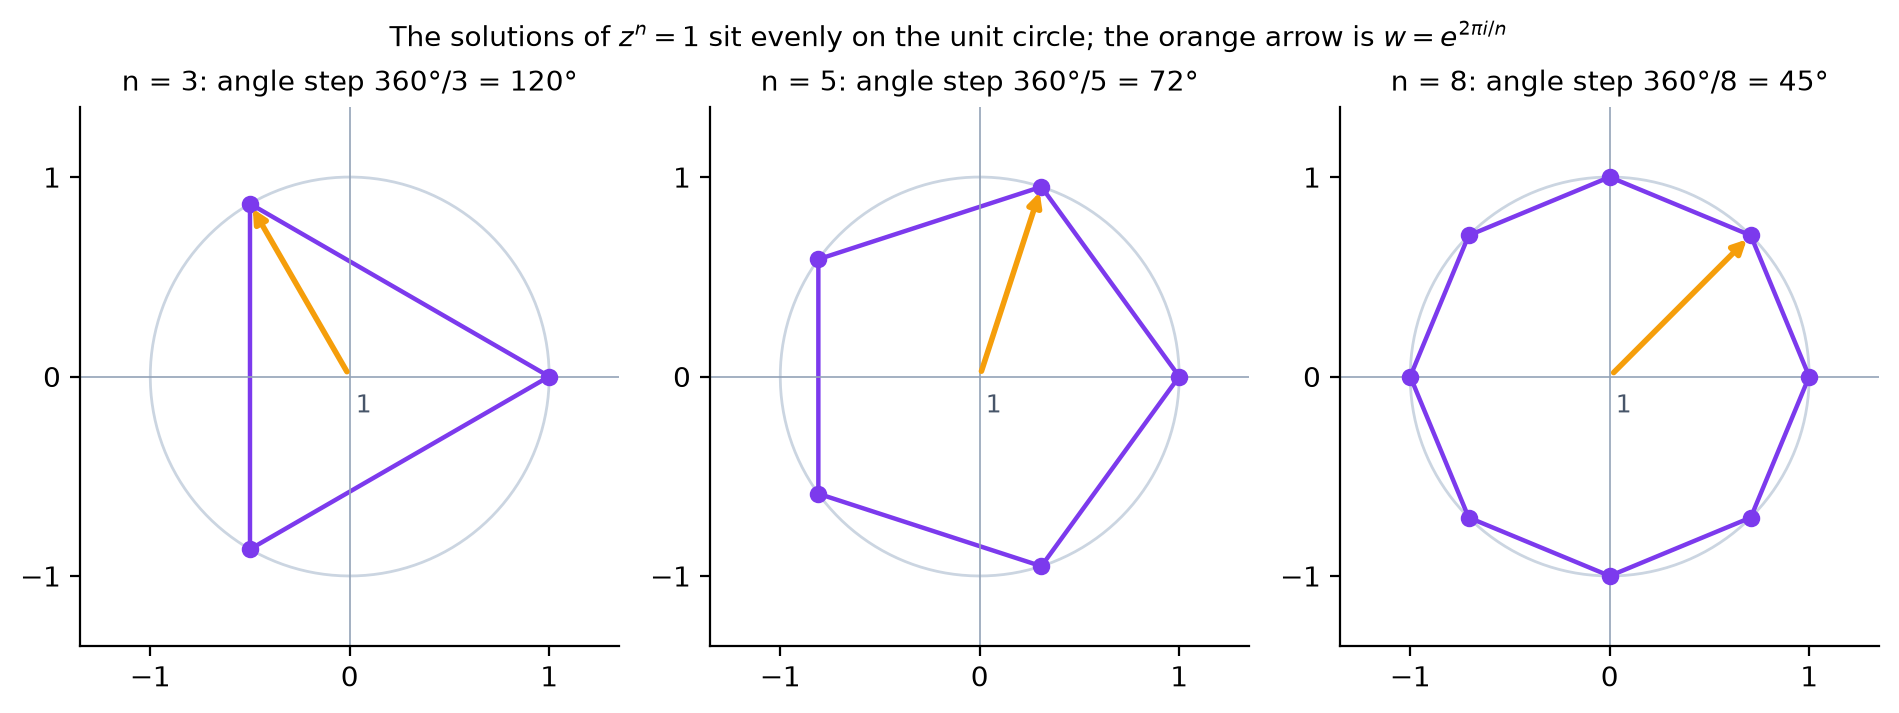

In [2]:
_show_mpl(_lessonfigs.roots_of_unity())

*Repeated multiplication by $w = e^{2\pi i/n}$ walks around the unit circle in equal steps. After $n$ steps it returns to 1, so these points solve $z^n = 1$.*

## Relative phase decides how arrows add

Add two arrows of length 1 whose angles differ by $\varphi$. Using [](#eq-l3-01-zzbar),

$$
|1 + e^{i\varphi}|^2 = (1 + e^{i\varphi})(1 + e^{-i\varphi}) = 2 + e^{i\varphi} + e^{-i\varphi} = 2 + 2\cos\varphi
$$ (eq-l3-01-sum)

:::{figure} ../../_static/animations/l3_01_multiply_rotates.mp4
:alt: An arrow 2 + i turned a quarter turn into -1 + 2i, then two unit arrows added head to tail while the second one turns, with a graph of the squared length.
:width: 100%

Multiplication by $i$ turns the plane; then the sum $1 + e^{i\varphi}$ swings from length 2 to 0 and back as $\varphi$ goes once around.
:::

:::{dropdown} What the animation shows
First the arrow $z = 2 + i$ rotates by a quarter turn into $iz = -1 + 2i$, keeping its length, because $i = e^{i\pi/2}$. Then a blue arrow 1 and an orange arrow $e^{i\varphi}$ are placed head to tail, with their red sum. As $\varphi$ sweeps from 0 to $2\pi$, a graph traces the squared length of the sum, $2 + 2\cos\varphi$: it is 4 when the arrows point the same way and 0 when they point opposite ways.
:::


In [3]:
_show(_lessonfigs.phase_sum())

**Explore.** Drag the slider to change the relative phase $\varphi$. The red point on the right is the squared length of the red sum arrow on the left.

:::{dropdown} What the figure shows
The first panel shows the arrows $1$ and $e^{i\varphi}$ head to tail and their sum. The second panel plots $|1 + e^{i\varphi}|^2 = 2 + 2\cos\varphi$ for $\varphi$ from $0^\circ$ to $360^\circ$, with a marker at the chosen phase: 4 at $0^\circ$, 2 at $90^\circ$, 0 at $180^\circ$.
:::

In step ($\varphi = 0$) the squared length is 4, twice the sum of the separate squared lengths. Opposite ($\varphi = \pi$) it is 0. On average over $\varphi$ it is 2, the same as adding the squared lengths. This is the arithmetic behind interference, which [L5-03](#lesson-l5-03) uses for quantum amplitudes.

## Compute it

Python has complex numbers built in (`1j` is $i$), and `cmath` gives modulus and argument. Run the cell and change `z`.


In [4]:
import cmath

z = 3 + 4j
r, theta = abs(z), cmath.phase(z)
print('modulus', r, ' argument (rad)', round(theta, 3))
print('conjugate', z.conjugate(), ' z * conj(z) =', z * z.conjugate())
print('polar back to Cartesian:', cmath.rect(r, theta))

# multiplying by i is a quarter turn
w = 2 + 1j
print('i * (2 + i) =', 1j * w, ' same length:', abs(w), abs(1j * w))

# |1 + e^{i phi}|^2 = 2 + 2 cos(phi)
for deg in (0, 90, 180):
    phi = cmath.pi * deg / 180
    print(deg, round(abs(1 + cmath.exp(1j * phi)) ** 2, 6), round(2 + 2 * cmath.cos(phi).real, 6))

modulus 5.0  argument (rad) 0.927
conjugate (3-4j)  z * conj(z) = (25+0j)
polar back to Cartesian: (3.0000000000000004+3.9999999999999996j)
i * (2 + i) = (-1+2j)  same length: 2.23606797749979 2.23606797749979
0 4.0 4.0
90 2.0 2.0
180 0.0 0.0


:::{prf:remark} Why the argument needs care
The angle is defined only up to adding $2\pi$. Software returns a principal value in $(-\pi, \pi]$; `cmath.phase(-1)` is $\pi$, and `cmath.phase(-1-1e-17j)` is close to $-\pi$. Differences of phases are what matter physically.
:::

## Worked example

:::{admonition} From coordinates to polar form and back
:class: tip

Let $z = -1 + i\sqrt{3}$. Find $|z|$, $\arg z$, the polar form, and $z^3$.

1. Modulus: $|z| = \sqrt{(-1)^2 + (\sqrt3)^2} = \sqrt{4} = 2$.
2. Argument: the point is in the second quadrant with $\cos\theta = -1/2$ and $\sin\theta = \sqrt3/2$, so $\theta = 2\pi/3$ ($120^\circ$).
3. Polar form: $z = 2e^{2\pi i/3}$.
4. Power: $z^3 = 2^3 e^{3 \cdot 2\pi i/3} = 8e^{2\pi i} = 8$. Check by expanding $(-1 + i\sqrt3)^2 = -2 - 2i\sqrt3$, then multiplying by $-1 + i\sqrt3$ to get $8$.

**Result.** $z = 2e^{2\pi i/3}$ and $z^3 = 8$: cubing multiplies the length by itself three times and triples the angle.
:::

## Exercises

**1. (Core)** For $z = 5 - 12i$, find $|z|$, $\bar z$ and $z\bar z$.

:::{dropdown} Solution
$|z| = \sqrt{25 + 144} = 13$, $\bar z = 5 + 12i$, and $z\bar z = 169 = 13^2$.
:::

**2. (Core)** Write $z = 1 + i$ in polar form and compute $z^8$.

:::{dropdown} Solution
$|z| = \sqrt2$ and $\arg z = \pi/4$, so $z = \sqrt2\,e^{i\pi/4}$. Then $z^8 = (\sqrt2)^8 e^{2\pi i} = 16$.
:::

**3. (Stretch)** Show that $|zw| = |z||w|$ for any complex $z, w$ using only $|u|^2 = u\bar u$.

:::{dropdown} Solution
$|zw|^2 = zw\,\overline{zw} = zw\,\bar z\bar w = (z\bar z)(w\bar w) = |z|^2|w|^2$, and moduli are non-negative, so $|zw| = |z||w|$.
:::

**4. (Stretch)** For which phases $\varphi$ is $|1 + e^{i\varphi}|^2$ equal to 1? What fraction of the in-step value is that?

:::{dropdown} Solution
$2 + 2\cos\varphi = 1$ gives $\cos\varphi = -1/2$, so $\varphi = 2\pi/3$ or $4\pi/3$. That is $1/4$ of the in-step value 4.
:::

**5. (Challenge)** Add $n$ unit arrows with angles $0, \varphi, 2\varphi, \dots, (n-1)\varphi$. Show that the squared length of the sum is $\sin^2(n\varphi/2)/\sin^2(\varphi/2)$ when $\varphi$ is not a multiple of $2\pi$.

:::{dropdown} Solution
The sum is a geometric series: $S = \sum_{k=0}^{n-1} e^{ik\varphi} = (e^{in\varphi} - 1)/(e^{i\varphi} - 1)$. Use $e^{ix} - 1 = e^{ix/2}\,2i\sin(x/2)$ for numerator and denominator. The phases have modulus 1, so $|S| = |\sin(n\varphi/2)|/|\sin(\varphi/2)|$. For $n = 2$ this gives $\sin^2\varphi/\sin^2(\varphi/2) = 4\cos^2(\varphi/2) = 2 + 2\cos\varphi$, matching [](#eq-l3-01-sum).
:::

## Check your understanding

**1. What is $z\bar z$ for $z = 3 + 4i$?**

- **A.** $25i$
- **B.** $7$
- **C.** $9 - 16$
- **D.** 25

:::{dropdown} Show the answer
**D. 25**

$z\bar z = (3 + 4i)(3 - 4i) = 9 - 12i + 12i - 16i^2 = 9 + 16 = 25$, which is $|z|^2$.
:::

**2. What does multiplying a complex number by $e^{i\pi/3}$ do to its arrow?**

- **A.** Multiplies its length by $\pi/3$
- **B.** Reflects it in the real axis
- **C.** Adds $\pi/3$ to its real part
- **D.** Turns it by $60^\circ$ and keeps its length

:::{dropdown} Show the answer
**D. Turns it by $60^\circ$ and keeps its length**

$|e^{i\pi/3}| = 1$, and angles add under multiplication, so the arrow turns by $\pi/3 = 60^\circ$ with its length unchanged.
:::

**3. Two unit arrows point in exactly opposite directions. What is the squared length of their sum?**

- **A.** 1
- **B.** 0
- **C.** 2
- **D.** 4

:::{dropdown} Show the answer
**B. 0**

Opposite directions means $\varphi = \pi$, and $2 + 2\cos\pi = 0$: the arrows cancel.
:::

**4. A two-outcome state vector has amplitudes $(\cos t, \sin t)$. What do the chances of the two outcomes add to?** *(Review of [L2-09](#lesson-l2-09))*

- **A.** Always $\cos t + \sin t$
- **B.** Always 2
- **C.** It depends on $t$
- **D.** Always 1

:::{dropdown} Show the answer
**D. Always 1**

The chances are $\cos^2 t$ and $\sin^2 t$, and $\cos^2 t + \sin^2 t = 1$ for every $t$. Complex amplitudes keep this rule with $|\alpha|^2 + |\beta|^2 = 1$.
:::

## Common misconceptions

- **"$i$ is imaginary, so it is not a real tool."** $i$ is just the number whose square is $-1$. Geometrically it is a quarter turn, and it makes rotations and waves easy to compute.
- **"Phase does not matter because probabilities only use $|z|^2$."** The phase of one number alone does not change $|z|^2$, but the relative phase of two numbers changes $|z_1 + z_2|^2$ from $(|z_1| + |z_2|)^2$ down to $(|z_1| - |z_2|)^2$.
- **"The argument of $z$ is $\arctan(b/a)$."** That formula loses the quadrant: $-1 - i$ and $1 + i$ give the same ratio. Use both $\cos\theta = a/|z|$ and $\sin\theta = b/|z|$ (the two-argument arctangent).

:::{caution} Scope and limits
This lesson treats complex numbers as a mathematical tool. Saying that amplitudes are complex does not by itself explain any physical experiment; that needs the measurement rules of quantum theory introduced in Level 5.
:::

:::{seealso} Where this leads
Complex amplitudes and relative phase return in [L3-02](#lesson-l3-02) as inner products of complex vectors, and in quantum gates as unitary rotations. Up to normalization, the formula $2 + 2\cos\varphi$ is the interference pattern of the Mach-Zehnder interferometer.
:::

:::{dropdown} For instructors

**Why this lesson.** Students meet complex numbers as algebra rules; quantum information needs them as geometry. Linking multiplication to rotation and conjugation to reflection makes later unitary and inner-product arguments visual [@openstax_polar; @feynman].

**Teaching notes.**

- Start from the in-step and opposite cases of two arrows before any formula; students predict 2 and 0 for the length, then check $4$ and $0$ for the squared length.
- Insist on the two-argument arctangent; give $-1 - i$ as a test case.
- Use the interactive figure to show that the average of $2 + 2\cos\varphi$ over a full turn is 2, the sum of the separate squared lengths.

**Assessment.** Exercise 3 (multiplicativity of the modulus) and the challenge exercise show whether students can move between algebraic and geometric reasoning; the check questions test the core computations.

**Going further.** Derive De Moivre's formula $(\cos\theta + i\sin\theta)^n = \cos n\theta + i\sin n\theta$ and use it to find $\cos 3\theta$ in terms of $\cos\theta$. The Feynman Lectures, Volume III, chapter 1, uses arrows of this kind for amplitudes [@feynman].

:::

## References

This lesson draws on [@openstax_polar; @feynman; @nielsenchuang].

**Further reading.**

- [@nielsenchuang]: Section 2.1 reviews the complex linear algebra used from Level 5 on.

**Next:** [L3-02 · Vectors and inner products](#lesson-l3-02)
